In [ ]:
# 3. Develop an FNN model to classify grayscale hand gesture images into 
# their corresponding alphabet classes. Display any five test images along 
# # with their actual and predicted alphabet labels. 

In [1]:
# Step 1: Import required libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [2]:
# Step 2: Load datasets
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

In [3]:
# Step 3: Separate images and labels
X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

In [4]:
# Step 4: Convert labels into 24 consecutive classes
classes = np.sort(np.unique(y_train))
label_map = {label: i for i, label in enumerate(classes)}

y_train = np.array([label_map[x] for x in y_train])
y_test = np.array([label_map[x] for x in y_test])

In [5]:
# Step 5: Normalize pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

In [6]:
# Step 6: Flatten images (28 x 28 = 784)
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

In [7]:
# Step 7: Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [8]:
# Step 8: Build Feedforward Neural Network
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(24, activation='softmax')
])

In [9]:
# Step 9: Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
# Step 10: Train the model
model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.2739 - loss: 2.3716 - val_accuracy: 0.4520 - val_loss: 1.7556
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.5427 - loss: 1.4487 - val_accuracy: 0.6192 - val_loss: 1.1967
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.6594 - loss: 1.0638 - val_accuracy: 0.7092 - val_loss: 0.9032
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.7367 - loss: 0.8258 - val_accuracy: 0.7785 - val_loss: 0.6976
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7927 - loss: 0.6519 - val_accuracy: 0.8062 - val_loss: 0.5711
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8337 - loss: 0.5172 - val_accuracy: 0.8567 - val_loss: 0.4415
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8690 - loss: 0.4116 - val_accuracy: 0.8862 - val_loss: 0.3582
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9061 - loss: 0.3141 - val_accu

In [11]:
# Step 11: Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy: {:.2f}%".format(test_accuracy * 100))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7101 - loss: 1.3192
Test Accuracy: 71.01%


In [12]:
# Step 12: Predict test images
predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)

# Convert numeric labels into alphabet letters
actual_letters = [chr(classes[label] + 65) for label in y_test]
predicted_letters = [
    chr(classes[label] + 65) for label in predicted_labels
]

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


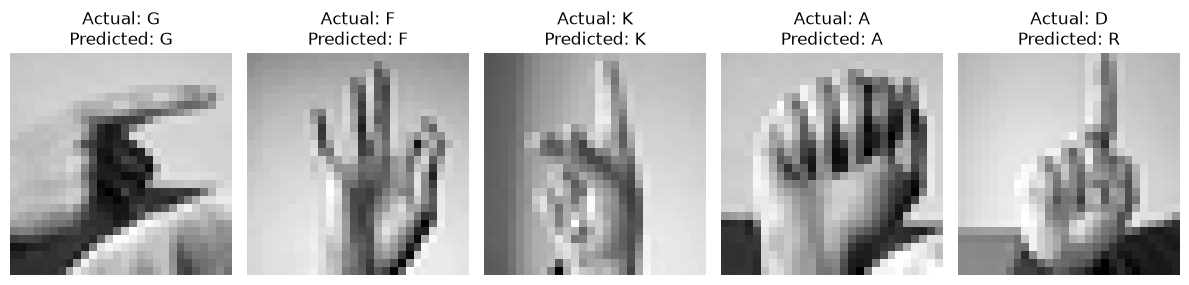

In [13]:
# Step 13: Display five test images
plt.figure(figsize=(12, 6))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    # Display grayscale image
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    # Display actual and predicted labels
    plt.title(
        f"Actual: {actual_letters[i]}\n"
        f"Predicted: {predicted_letters[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()